# Section 2: Data Exploration

**Student: Yuanjie-Tan**  
**GitHub username:Yuanjie-Tan**  
**Date:2026/08/04**  

## Goal

Produce one reproducible exploratory data analysis of a high-dimensional polymer dataset and use evidence from the analysis to answer the section's critical-thinking questions.

This is one integrated assignment, not three separate daily tasks. Organize the work in whatever order helps you build a coherent analysis.

## How to Use This Notebook

1. Copy this template to `sections/s02/submissions/<github-username>/s02_data_exploration.ipynb`.
2. Add your code only to the blank code cells.
3. Add explanations and answers to the blank Markdown cells.
4. You may add more cells when useful, but keep the section headings and required evidence.
5. Keep the raw CSV unchanged. Perform and explain any cleaning in this notebook.
6. Before submission, restart the kernel and run every cell from top to bottom.

Aim for a focused notebook that can be rerun and discussed, not a gallery of every possible chart. Clear labels, units, short interpretations, and well-chosen evidence matter more than decoration.

## Python Setup and Suggested Packages

From the repository root, install the course tools into your `uv` environment:

```bash
uv pip install pandas numpy matplotlib seaborn scikit-learn ipykernel
```

Select the project's `.venv` Python kernel in VS Code or Jupyter. These are the suggested imports:

```python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
```

What each package is for:

| Package | Use in this notebook |
|---|---|
| `pandas` | Load the CSV, select columns, audit values, calculate statistics and correlations, and build labeled result tables |
| `numpy` | Check numerical results, calculate cumulative variance, and work with arrays returned by scikit-learn |
| `matplotlib` | Create figures and control titles, axes, labels, and layout |
| `seaborn` | Create readable statistical plots such as histograms, box plots, heatmaps, and scatter plots |
| `scikit-learn` | Standardize the properties with `StandardScaler` and calculate PCA with `PCA` |

You may use equivalent tools, but you must explain the substitution and produce the same required evidence.

## Quick Function Reference

Use this table as a map, not as a list of functions that must all appear in your notebook.

| Task | Suggested functions or attributes | What to check |
|---|---|---|
| Load data | `pd.read_csv()` | The path is relative and the result is a DataFrame |
| Preview structure | `.head()`, `.shape`, `.columns`, `.info()`, `.dtypes` | Rows and columns mean what you think they mean |
| Missingness and duplicates | `.isna().sum()`, `.duplicated().sum()`, `.nunique()` | Non-null values can still be suspicious |
| Select analytical variables | `.select_dtypes(include="number")`, `.drop(columns=...)` | Explicitly remove `id`; save the 13 property names |
| Descriptive statistics | `.describe()`, `.mean()`, `.median()`, `.var()`, `.std()`, `.quantile()` | Label statistics and preserve units |
| Inspect selected rows | `.loc[]`, `.sort_values()`, Boolean filters | Look at the original records behind unusual points |
| Distribution plots | `sns.histplot()`, optional `kde=True` | Bins and smoothing choices affect appearance |
| Box plots | `sns.boxplot()` | Whisker points are flags for investigation, not automatic errors |
| Correlations | `.corr(method="pearson")`, `.corr(method="spearman")` | Correlation measures association, not causation |
| Correlation heatmaps | `sns.heatmap()` | Keep labels readable and use a scale centered at zero |
| Relationship plots | `sns.scatterplot()` or `plt.scatter()` | Look for curves, groups, ties, and influential values |
| Standardization | `StandardScaler()`, `.fit_transform()`, `.mean_`, `.scale_` | PCA input should have approximately zero column means and unit population variance |
| PCA | `PCA()`, `.fit_transform()`, `.explained_variance_ratio_`, `.components_` | Know the shape and meaning of every returned array |
| Cumulative variance | `np.cumsum()` | Decide how many components meet your stated purpose |
| PCA plots | `plt.plot()`, `plt.bar()`, `plt.scatter()` | Label component numbers and variance percentages |
| Labeled tables | `pd.DataFrame()` | Attach property names to component weights |

Useful habit: after every major transformation, print or display its type and shape before plotting it.

## Dataset

Analyze `sections/s02/homework/openpoly_calculated_properties.csv` and read `sections/s02/homework/DATASET.md` before beginning.

The CSV contains 1,000 calculated polymers, identity and structure fields, metadata, and 13 numeric quantum-chemical properties. Use those 13 properties for the main multivariate analysis. Exclude `id`: it is an identifier, not a measured or calculated polymer property.

Load the CSV using a repository-relative path. The notebook must not depend on an absolute path from your computer.

In [1]:
# Fix the working directory to the repository root so that all relative paths below
# are computed from the repo root, regardless of which directory the kernel starts in.
import os
cwd = os.getcwd()
root = cwd
for _ in range(6):
    if os.path.isdir(os.path.join(root, "sections")):
        break
    parent = os.path.dirname(root)
    if parent == root:
        break
    root = parent
os.chdir(root)
print("Current cwd:", os.getcwd())

# 1. Import the libraries (Explanation)
import pandas as pd                  # tabular data handling
import numpy as np                   # numeric computation
import matplotlib.pyplot as plt      # plotting
import seaborn as sns                # nicer statistical plots
from sklearn.preprocessing import StandardScaler  # z-score standardization
from sklearn.decomposition import PCA            # principal component analysis

# 2. Load the CSV using a repository-relative path (not an absolute path)
df = pd.read_csv("sections/s02/homework/openpoly_calculated_properties.csv")
print("Data shape:", df.shape)   # (1000, 23): 1000 rows, 23 columns

# 3. Select the 13 numeric property columns.
#    select_dtypes(include=["float64","int64"]) keeps only numeric columns.
#    remove("id") drops the identifier, which is not a physical property.
property_cols = df.select_dtypes(include=["float64", "int64"]).columns.tolist()
property_cols.remove("id")
print("13 numeric property columns:", property_cols)
print("Count:", len(property_cols))

Current cwd: /home/administrator/course


Data shape: (1000, 23)
13 numeric property columns: ['Energy_Hatree', 'es', 'Isotropic_Polarizability_au', 'HOMO_eV', 'LUMO_eV', 'Inner_energy_correction_Hatree', 'Thermal_correction_to_Enthalpy_Hatree', 'Thermal_correction_to_Gibbs_Free_Energy_Hatree', 'Entropy_Hatree', 'Dipole_Debye', 'Gibbs_Free_Energy_Hatree', 'Enthalpy_Hatree', 'HOMO_LUMO_Gap_eV']
Count: 13


## 1. Audit the Dataset

Use the blank cells below to:

- report the dataset's shape, column names, data types, missing-value counts, exact duplicates, and number of unique values per column;
- create a compact data dictionary that classifies columns as identifiers, chemical structures, categorical metadata, or numeric analytical variables;
- inspect zeros, extreme values, and constant columns; and
- identify at least two values or patterns that need investigation, even if pandas reports no missing values.

Do not decide that a value is valid merely because it is non-null. Do not delete an observation without documenting the evidence and reasoning.

In [2]:
# ================= Part 1: Audit the Dataset =================

# --- 1. Overall structure ---
print("Shape (rows, columns):", df.shape)
print()
print("Data types per column:")
print(df.dtypes)
print()
print("First 5 rows:")
df.head()

# --- 2. Missing values ---
print("Missing values per column:")
print(df.isna().sum())   # pandas reports no explicit NaN -> but non-null != valid

# --- 3. Exact duplicate rows ---
print("Number of exact duplicate rows:", df.duplicated().sum())

# --- 4. Unique value count per column ---
print("Unique values per column:")
print(df.nunique())

# --- 5. Audit the numeric property columns ---
# Note: the raw CSV has 1000 rows. Use only the 13 numeric properties here.
numeric_df = df[property_cols]

# 5a. Descriptive statistics (check min/max/mean to spot extremes)
print("Descriptive statistics of the 13 numeric properties:")
numeric_df.describe()

# 5b. Count rows equal to 0 (DATASET.md warns: 0 may indicate a missing/failed calc)
zero_counts = (numeric_df == 0).sum()
print("Number of rows == 0 per numeric column:")
print(zero_counts[zero_counts > 0])   # show only columns that contain zeros

# 5c. Standard deviation (a std of 0 means the column is constant, not useful)
print("Standard deviation per column:")
print(numeric_df.std())

# 5d. Investigate rows where all "energy-type" properties are 0.
#     These are likely missing calculations, not real physical values.
mask_energy0 = df["Energy_Hatree"] == 0
print("Rows with Energy_Hatree == 0:", mask_energy0.sum(),
      "({:.1f}% of all rows)".format(100 * mask_energy0.sum() / len(df)))
print("Energy cannot be physically 0 here -> likely missing placeholder values.")

Shape (rows, columns): (1000, 23)

Data types per column:
id                                                  int64
Name                                                  str
reactant_1                                            str
reactant_2                                            str
psmiles                                               str
SMILES                                                str
reaction_type                                         str
Energy_Hatree                                     float64
es                                                float64
Isotropic_Polarizability_au                       float64
HOMO_eV                                           float64
LUMO_eV                                           float64
Inner_energy_correction_Hatree                    float64
Thermal_correction_to_Enthalpy_Hatree             float64
Thermal_correction_to_Gibbs_Free_Energy_Hatree    float64
Entropy_Hatree                                    float64
Dipole_Debye  

### Audit Findings

Summarize the dataset structure and your data-quality concerns below. Separate direct observations from interpretations.

**Structure (observation).** The dataset has 1,000 rows and 23 columns. It contains 2 identifiers (`id`, `Name`), 4 chemical-structure strings (`reactant_1`, `reactant_2`, `psmiles`, `SMILES`), 4 categorical metadata columns (`reaction_type`, `Software`, `Theory_Level`, `Source`), and 13 numeric quantum-chemical properties. Among the types, `id` is `int64`, the 13 properties are `float64`, and the remaining columns are strings (`str`).

**Missingness and duplicates (observation).** The `.isna().sum()` check reports 0 missing values in every column, and there are no exact duplicate rows. On its own, a zero missing-count suggests a complete dataset, but it only says there are no NaN entries — it does not certify that the values are physically meaningful.

**Constant metadata columns (observation).** The columns `reaction_type`, `Software`, `Theory_Level`, and `Source` each have only 1 unique value, and `Thermal_correction_to_Enthalpy_Hatree` has only 2. Because every row shares the same reaction type (`Polyamidation`), the same software (`ORCA`), and the same theory level, these metadata columns cannot distinguish one polymer from another.

**Suspicious zeros (observation).** 74 rows (7.4%) have `Energy_Hatree`, `Isotropic_Polarizability_au`, `HOMO_eV`, `LUMO_eV`, and `HOMO_LUMO_Gap_eV` equal to 0; another 36 rows have several correction, Gibbs, and enthalpy properties equal to 0. For `Energy_Hatree`, the `describe()` output shows `min = -9263.85` but `max = 0.0`, confirming real zeros rather than legitimate small values.

**Interpretation.** A missing count of zero does not prove the data is complete: a real molecular energy is negative and on the order of ~1000, so a value of exactly 0 is physically impossible. These zeros are almost certainly missing or failed calculations stored as placeholder values. The constant metadata columns are of no use for analysis because they carry no variation. I record these concerns here rather than deleting rows, because data-quality decisions should rest on documented evidence and reasoning, not on the fact that a cell is non-null.

## 2. Describe and Visualize Distributions

Use the blank cells below to:

- report count, mean, median, variance, standard deviation, minimum, quartiles, and maximum for all 13 numeric properties;
- create distribution plots and box plots for at least six properties covering different units and scales;
- investigate at least three observations that a box plot or distribution plot makes look unusual; and
- discuss at least three properties using **observation → interpretation → limitation**, including one case where the mean and median lead to different impressions.

A point beyond a box-plot whisker is unusual under the plot's rule; it is not automatically an error.

In [3]:
# ============ Part 2: Describe and Visualize Distributions ============

# --- 1. Full descriptive statistics of the 13 numeric properties ---
# describe() gives count/mean/std/min/25%/50%/75%/max
desc = numeric_df.describe()
# Add median and variance explicitly, as required by the assignment
full_desc = desc.copy()
full_desc.loc["median"] = numeric_df.median()
full_desc.loc["variance"] = numeric_df.var()
print("Full descriptive statistics of the 13 numeric properties:")
print(full_desc)

Full descriptive statistics of the 13 numeric properties:
          Energy_Hatree           es  Isotropic_Polarizability_au  \
count      1.000000e+03  1000.000000                  1000.000000   
mean      -2.121316e+03     0.965277                   255.059933   
std        1.338864e+03     0.073968                    92.646975   
min       -9.263852e+03     0.500488                    -0.036470   
25%       -2.759187e+03     0.974565                   230.452925   
50%       -1.692087e+03     0.996496                   263.660670   
75%       -1.330984e+03     0.998829                   296.523985   
max        0.000000e+00     0.999748                   674.733350   
median    -1.692087e+03     0.996496                   263.660670   
variance   1.792557e+06     0.005471                  8583.461965   

              HOMO_eV      LUMO_eV  Inner_energy_correction_Hatree  \
count     1000.000000  1000.000000                     1000.000000   
mean        -7.865487    -0.172145        

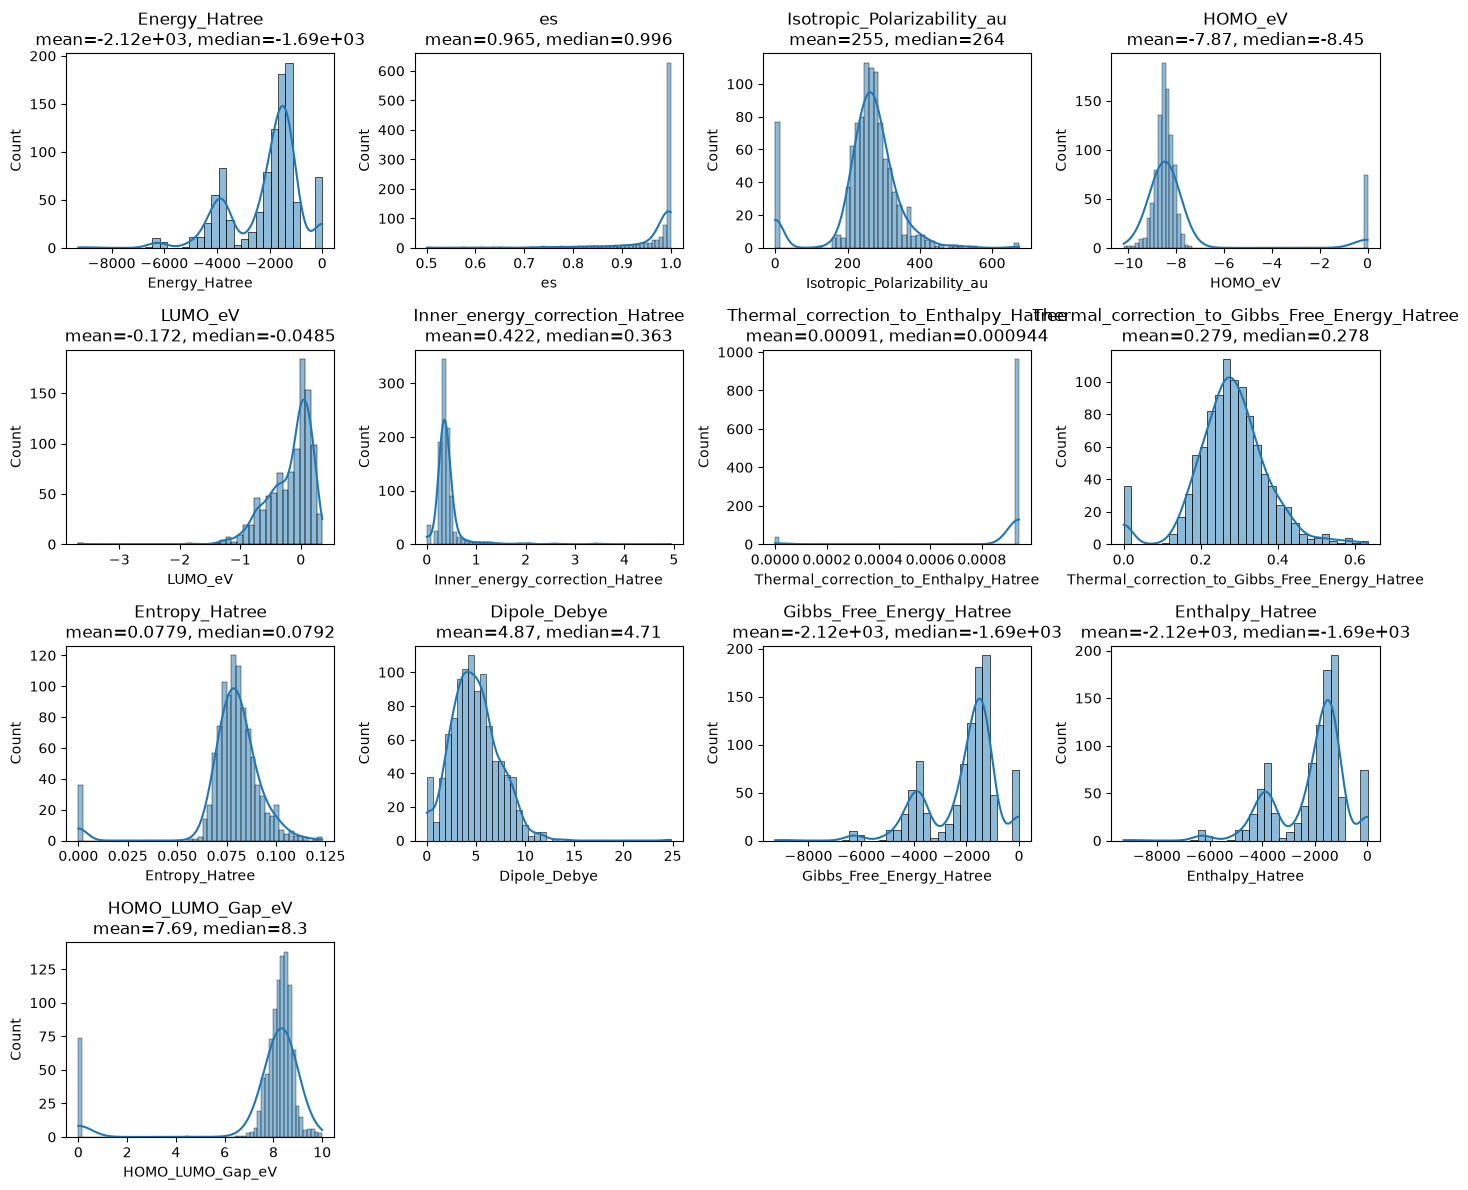

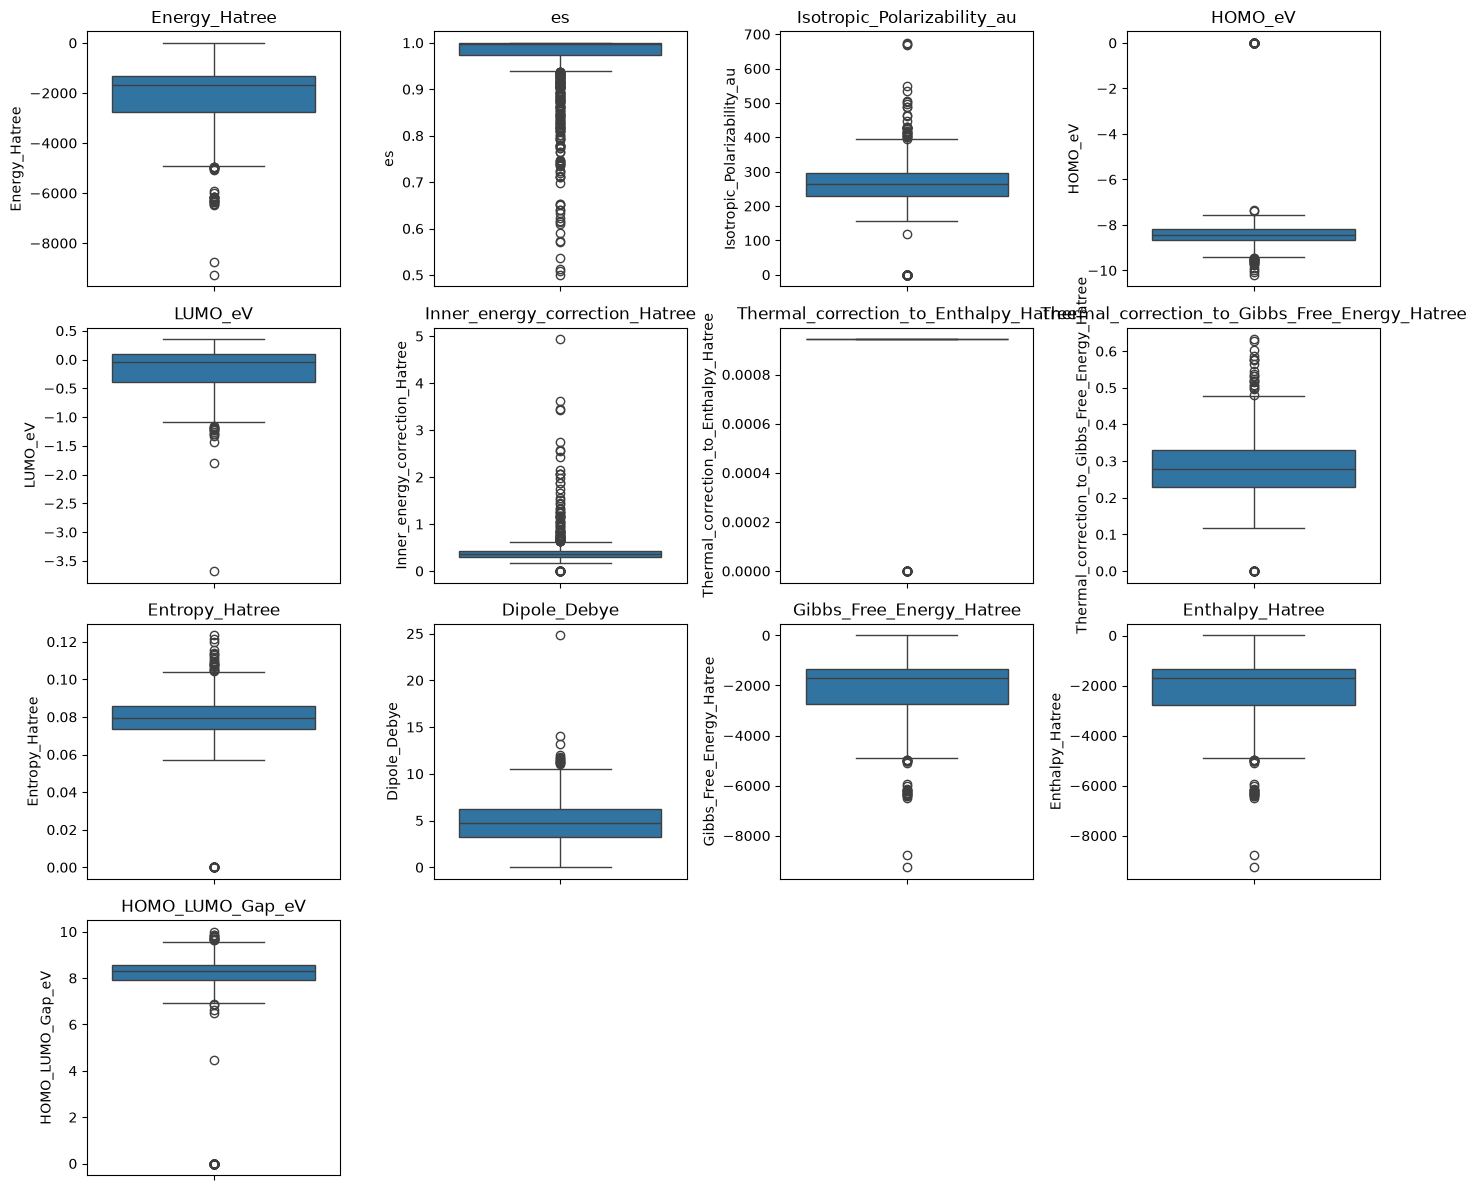

Rows with the largest 3 Energy_Hatree (original records):
Rows with the largest 3 LUMO_eV:


,Name,LUMO_eV,HOMO_eV,HOMO_LUMO_Gap_eV
232,OMG_polymer_201595,0.3538,-8.1405,8.4943
317,OMG_polymer_162267,0.3486,-7.7864,8.1350
159,OMG_polymer_168059,0.3256,-9.4473,9.7729


In [4]:
# --- 2. Distribution plots: histograms for ALL 13 numeric properties ---
# Note: different properties use different units (Hartree, eV, au, Debye...),
# so each distribution is examined individually rather than mixed together.
props_to_plot = property_cols   # plot all 13 properties
n = len(props_to_plot)
# Arrange 13 subplots in 4 rows x 4 columns (last cell left empty)
fig, axes = plt.subplots(4, 4, figsize=(14, 12))
axes = axes.flatten()
for ax, col in zip(axes, props_to_plot):
    sns.histplot(numeric_df[col], kde=True, ax=ax)
    ax.set_title(f"{col}\nmean={numeric_df[col].mean():.3g}, median={numeric_df[col].median():.3g}")
# Hide the unused last subplot
for ax in axes[n:]:
    ax.axis('off')
plt.tight_layout()
plt.show()

# --- 3. Box plots for ALL 13 properties: reveal outliers ---
# Box plots quickly expose outliers (points beyond the whiskers).
# Note: a box-plot outlier is not automatically an error, only unusual.
fig2, axes2 = plt.subplots(4, 4, figsize=(14, 12))
axes2 = axes2.flatten()
for ax, col in zip(axes2, props_to_plot):
    sns.boxplot(y=numeric_df[col], ax=ax)
    ax.set_title(col)
for ax in axes2[n:]:
    ax.axis('off')
plt.tight_layout()
plt.show()

# --- 4. Investigate a few "unusual" observations ---
# Example: look at the original records behind the largest values.
print("Rows with the largest 3 Energy_Hatree (original records):")
df.nlargest(3, "Energy_Hatree")[["Name"] + property_cols].iloc[:, :4]
print("Rows with the largest 3 LUMO_eV:")
df.nlargest(3, "LUMO_eV")[["Name","LUMO_eV","HOMO_eV","HOMO_LUMO_Gap_eV"]]

### Distribution Findings

For at least three properties, record an observation, one plausible interpretation, and a limitation below. Cite the relevant statistic, row, or plot.

**Energy_Hatree.** *(Observation)* The mean is −2121.3 while the median is −1692.1, so the mean lies well below the median; the minimum is −9263.9 and the maximum is 0.0, with a skewness of −1.06. *(Interpretation)* The mean below the median and the negative skewness indicate a left-skewed distribution pulled by a few very negative energies (min ≈ −9264). The maximum being exactly 0 is not a real molecule: molecular total energies are negative and on the order of thousands, so these 74 zeros are missing or failed calculations stored as placeholder values. *(Limitation)* The mean–median gap alone cannot separate genuine extreme polymers from placeholder zeros; that requires explicitly flagging the values that equal 0, or the underlying calculation logs.

**HOMO_eV.** *(Observation)* The bulk of the distribution sits between about −10 and −7 eV (92.4% of the values fall in this range), with a median of −8.45 and interquartile range from −8.67 to −8.17. The mean (−7.87) is above the median and the skewness is +3.11, so the distribution is right-skewed, and the maximum is 0.0 (74 rows equal 0). *(Interpretation)* Real HOMO levels of these polymers cluster tightly near −8 eV, so the rightward skew and the value 0 are not a genuine chemical range; they are the same 74 failed calculations stored as placeholder zeros, which form a tail toward 0. *(Limitation)* The histogram shows the 0-tail clearly, but isna-like checks would miss it; only explicitly counting `== 0` reveals it.

**Dipole_Debye.** *(Observation)* The histogram shows a main body that looks roughly normal around the median (≈4.71), but with a separate spike at exactly 0: 36 rows (3.6%) equal 0, and all of them coincide with the rows where `Energy_Hatree == 0`. Away from that spike the distribution is lightly right-skewed (skew ≈ 0.81) toward a few large values (max 24.8, a genuine high dipole). *(Interpretation)* Real dipole moments are positive continuous quantities clustered near the median, so a batch of 36 exact zeros that exactly matches the failed-calculation batch is a placeholder artifact, not a set of genuine symmetric molecules. *(Limitation)* A histogram alone cannot prove these zeros are missing rather than real; the evidence is the exact-zero coincidence with the failed rows and the absence of near-zero values elsewhere.

## 3. Examine Relationships

Use the blank cells below to:

- produce labeled Pearson and Spearman correlation heatmaps for the 13 numeric properties;
- identify at least two strong relationships and inspect each with an appropriate scatter plot;
- find at least one pair for which Pearson and Spearman differ meaningfully;
- explain what the difference suggests and what it does not prove; and
- check whether any properties are exact or near-exact mathematical combinations of others.

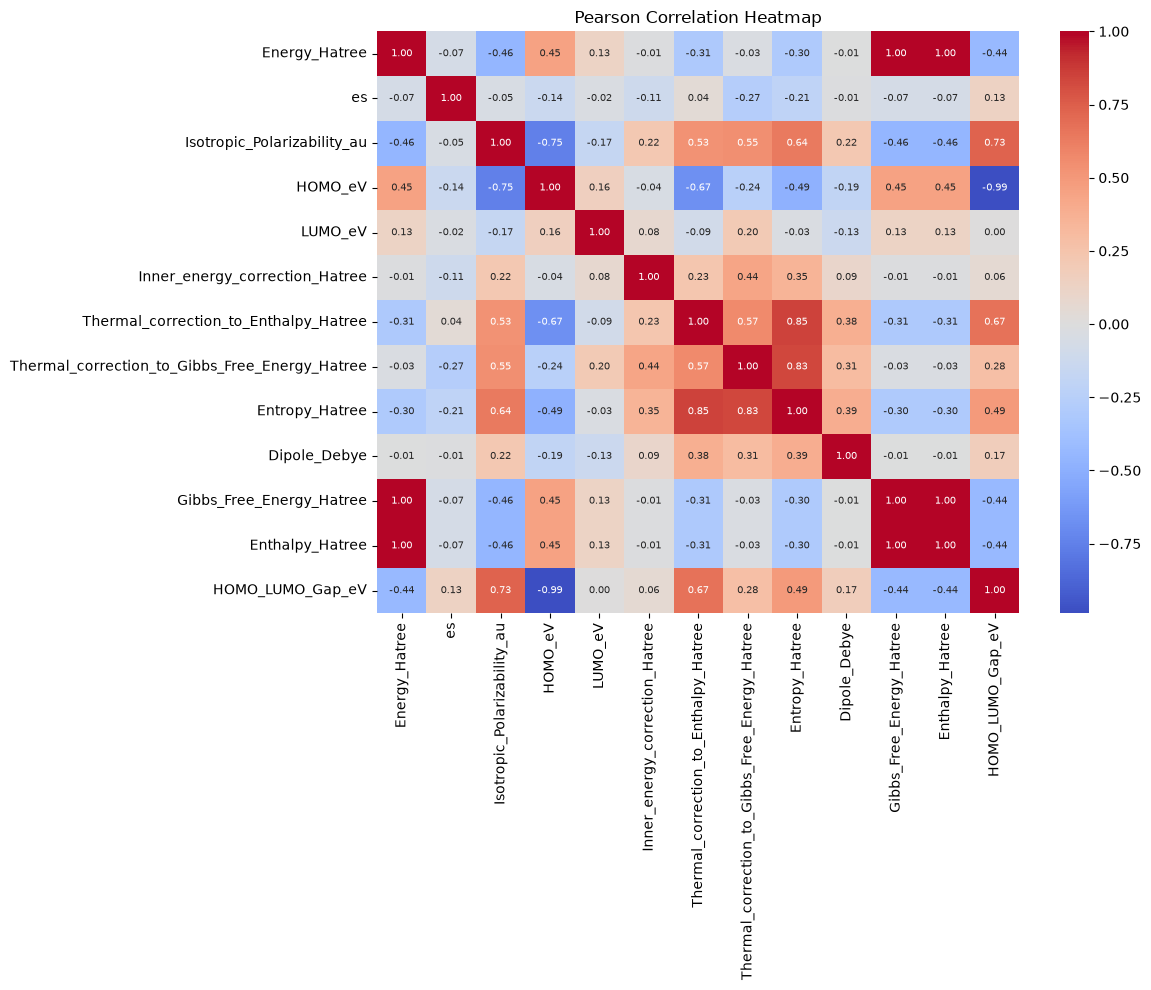

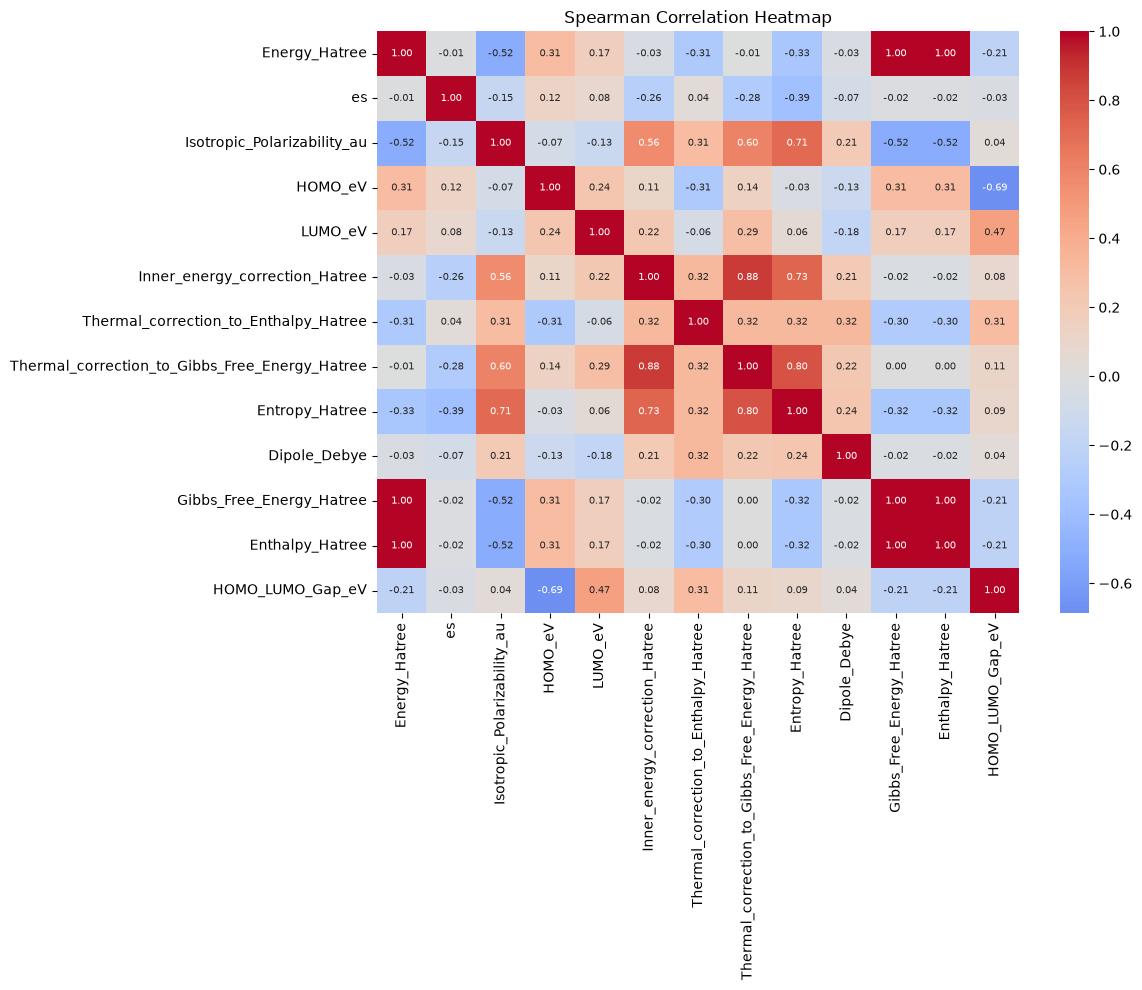

In [5]:
# ============ Part 3: Examine Relationships ============

# --- 1. Pearson correlation matrix + heatmap ---
# Pearson measures LINEAR correlation (best for variables related by a straight line).
pearson_corr = numeric_df.corr(method="pearson")
plt.figure(figsize=(12, 10))
sns.heatmap(pearson_corr, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, annot_kws={"size": 7})
plt.title("Pearson Correlation Heatmap")
plt.tight_layout()
plt.show()

# --- 2. Spearman correlation matrix + heatmap ---
# Spearman measures MONOTONIC correlation (more robust, not linear, less
# affected by outliers).
spearman_corr = numeric_df.corr(method="spearman")
plt.figure(figsize=(12, 10))
sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, annot_kws={"size": 7})
plt.title("Spearman Correlation Heatmap")
plt.tight_layout()
plt.show()

Strongest correlated pairs (unique, based on |Spearman|):
  Gibbs_Free_Energy_Hatree  ~  Enthalpy_Hatree  (|r|=1.000)
  Energy_Hatree  ~  Gibbs_Free_Energy_Hatree  (|r|=1.000)
  Energy_Hatree  ~  Enthalpy_Hatree  (|r|=1.000)
  Inner_energy_correction_Hatree  ~  Thermal_correction_to_Gibbs_Free_Energy_Hatree  (|r|=0.878)


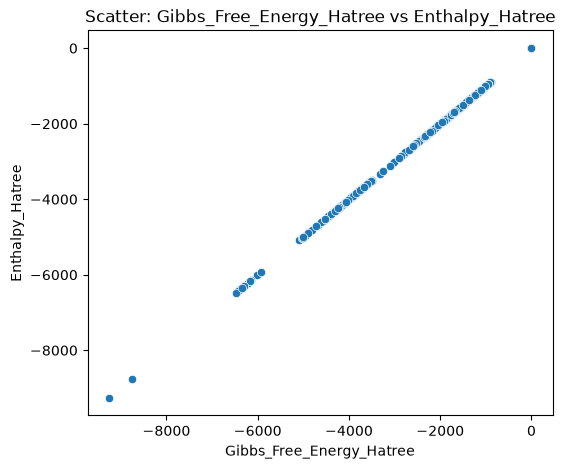

  Isotropic_Polarizability_au vs HOMO_eV: pearson=-0.749, spearman=-0.070, diff=0.679
  Isotropic_Polarizability_au vs Inner_energy_correction_Hatree: pearson=0.223, spearman=0.560, diff=0.337
  Isotropic_Polarizability_au vs HOMO_LUMO_Gap_eV: pearson=0.732, spearman=0.038, diff=0.694
  HOMO_eV vs Thermal_correction_to_Enthalpy_Hatree: pearson=-0.675, spearman=-0.310, diff=0.365
  HOMO_eV vs Thermal_correction_to_Gibbs_Free_Energy_Hatree: pearson=-0.244, spearman=0.140, diff=0.384
  HOMO_eV vs Entropy_Hatree: pearson=-0.488, spearman=-0.032, diff=0.456
  HOMO_eV vs HOMO_LUMO_Gap_eV: pearson=-0.987, spearman=-0.686, diff=0.301
  LUMO_eV vs HOMO_LUMO_Gap_eV: pearson=0.001, spearman=0.466, diff=0.464
  Inner_energy_correction_Hatree vs Thermal_correction_to_Gibbs_Free_Energy_Hatree: pearson=0.440, spearman=0.878, diff=0.438
  Inner_energy_correction_Hatree vs Entropy_Hatree: pearson=0.352, spearman=0.728, diff=0.377
  Thermal_correction_to_Enthalpy_Hatree vs Entropy_Hatree: pearson=0.851,

In [6]:
# --- 3. Find the strongest correlations and plot them ---
# Keep only UNIQUE unordered pairs (a,b) with a < b so (E,G) and (G,E) are not
# counted as two separate findings. Symmetric duplicates otherwise dominate the list.
corr_vals = spearman_corr.where(~np.eye(len(spearman_corr), dtype=bool)).stack()

# Build the list of (|r|, a, b) for unique pairs and sort descending
pairs = [(abs(spearman_corr.iloc[i, j]), spearman_corr.index[i], spearman_corr.columns[j])
         for i in range(len(property_cols))
         for j in range(i + 1, len(property_cols))]
pairs.sort(key=lambda t: t[0], reverse=True)

print("Strongest correlated pairs (unique, based on |Spearman|):")
for r, a, b in pairs[:4]:
    print(f"  {a}  ~  {b}  (|r|={r:.3f})")

# Scatter plot for the strongest pair
_, p1, p2 = pairs[0]
plt.figure(figsize=(6, 5))
sns.scatterplot(x=numeric_df[p1], y=numeric_df[p2])
plt.title(f"Scatter: {p1} vs {p2}")
plt.xlabel(p1); plt.ylabel(p2)
plt.show()

# --- 4. Look for a pair where Pearson and Spearman differ noticeably ---
# A large Pearson-Spearman difference usually signals a nonlinear monotonic
# relationship or strong influence of outliers.
for c1 in range(len(property_cols)):
    for c2 in range(c1+1, len(property_cols)):
        a, b = property_cols[c1], property_cols[c2]
        pr = numeric_df[a].corr(numeric_df[b], method="pearson")
        sp = numeric_df[a].corr(numeric_df[b], method="spearman")
        diff = abs(pr - sp)
        if diff > 0.3:   # print pairs where the difference exceeds 0.3 for analysis
            print(f"  {a} vs {b}: pearson={pr:.3f}, spearman={sp:.3f}, diff={diff:.3f}")

In [7]:
# --- 5. Evidence: is HOMO_LUMO_Gap_eV an independent property or a derived one? ---
# The gap is defined as LUMO - HOMO. Verify whether the data column exactly satisfies
# this identity. If it does, the gap carries no information that is not already present
# in HOMO_eV and LUMO_eV (a mathematical dependency, like the E/H/G family).
gap_diff = (numeric_df['HOMO_LUMO_Gap_eV'] - (numeric_df['LUMO_eV'] - numeric_df['HOMO_eV'])).abs()
print('max |Gap - (LUMO - HOMO)| =', gap_diff.max())
print('=> exactly a derived identity:', gap_diff.max() < 1e-9)


max |Gap - (LUMO - HOMO)| = 1.7763568394002505e-15
=> exactly a derived identity: True


### Relationship Findings

Explain the strongest relationships, the Pearson–Spearman contrast, and any mathematical dependencies below. Distinguish association from causation.

**Strongest relationship (mathematical dependency).** `Energy_Hatree`, `Enthalpy_Hatree`, and `Gibbs_Free_Energy_Hatree` are almost perfectly linearly correlated with one another (Pearson ≈ 1.000 for every pair). This is not three independent physical measurements: quantum-chemistry outputs define enthalpy as H = E + thermal_enthalpy and Gibbs energy as G = E + thermal_gibbs. In fact H − E averages only about 0.42 Hartree and G − E about 0.28, while E itself ranges over thousands, so H and G are essentially E plus a small correction. The three quantities are therefore near-identical linear functions of the single dominant quantity E, which confirms my hypothesis that each is computed from the same underlying quantity.

**An additional derived quantity.** The evidence cell in Part 3 shows that `HOMO_LUMO_Gap_eV` exactly equals `LUMO_eV - HOMO_eV` for every row (max absolute difference ≈ 1.8e-15, purely floating point). So the gap is a *derived* quantity, not an independent measurement: it carries no information beyond what HOMO and LUMO already hold. Correlations involving the gap should therefore be read with this dependency in mind, just like the E/H/G family.

**Pearson vs Spearman contrast.** Some pairs show a large gap between the two coefficients — for example `Isotropic_Polarizability_au` vs `HOMO_LUMO_Gap_eV` gives Pearson +0.73 but Spearman only +0.04. A large Pearson–Spearman gap means the correlation is driven by extreme values rather than by a steady monotonic relationship. Whether placeholder zeros distort a correlation depends on how large their share is among the valid values of each variable: the larger the share of placeholders in both variables, the stronger the artificial correlation they create. Pearson, which is sensitive to outliers, is the one most affected, while Spearman, a rank-based measure, is far more robust.

**Association vs causation.** A high correlation, even near 1.0, does not by itself prove that one variable can be derived from another or that one causes the other. The E/H/G relationship can be explained as a mathematical identity only because we already know the thermodynamic definitions; from the data alone, near-perfect correlation would remain only an association. These quantities are reference values produced by a particular calculation method, so strong correlation under one method is not sufficient evidence of a general derivable relationship.

## 4. Standardize and Run PCA

Use the blank cells below to:

- standardize the 13 numeric properties with `StandardScaler`;
- verify numerically that standardization worked;
- run PCA on the standardized values;
- create a scree or individual explained-variance plot;
- create a cumulative explained-variance plot;
- create a PC1-versus-PC2 scores plot; and
- create a loading table or loading plot for PC1 and PC2.

Then state how many components you would retain and justify the choice using both explained variance and the purpose of the analysis. Interpret the strongest PC1 and PC2 loadings, inspect unusual score-plot points, and state at least two limitations of the projection.

### PCA Tool Map

Work through these checkpoints in order:

1. **Build `X`:** select the 13 numeric analytical properties and exclude `id`. Expected shape: `(number of rows, 13)`.
2. **Keep the names:** save the 13 column names before converting or scaling; scikit-learn commonly returns NumPy arrays without those labels.
3. **Standardize:** create `StandardScaler`, then use `fit_transform(X)`. The scaled array should have the same shape as `X`.
4. **Verify scaling:** calculate column means and population standard deviations on the scaled array. They should be approximately 0 and 1. Small floating-point values such as `1e-16` count as approximately zero.
5. **Fit PCA:** start with `PCA()` without choosing a reduced component count so you can inspect all components. Use `fit_transform()` on the standardized array to obtain row scores.
6. **Inspect variance:** use `explained_variance_ratio_` for individual proportions and `np.cumsum()` for cumulative proportions. The proportions should sum to approximately 1.
7. **Inspect component weights:** `components_` has one row per principal component and one column per original property. Transpose it and construct a labeled DataFrame using the saved property names.
8. **Plot scores:** columns 0 and 1 of the transformed score array are PC1 and PC2 coordinates for each polymer row.
9. **Choose retention:** state a rule, such as a cumulative-variance threshold or a visualization goal, and explain the information lost by that choice.

Common mistakes to avoid:

- including `id` because it is numeric;
- running PCA on properties with different scales without standardizing;
- calling `.fit_transform()` separately on different subsets;
- losing the property names when constructing the component table;
- confusing PCA **scores** (row coordinates) with component **weights** (how original properties form each component);
- assuming a large component weight proves causation or predictive importance; and
- worrying if every sign in a component is reversed—PCA directions have arbitrary sign.

`StandardScaler` uses population variance (`ddof=0`). A pandas `.std()` call uses sample standard deviation by default, so use a consistent definition when verifying unit variance. `PCA` centers inputs internally but does not put differently scaled properties onto comparable units; that is why the separate standardization step is still required.

In [8]:
# ============ Part 4: Standardize and Run PCA ============

# --- 1. Build X: take only the 13 numeric properties ---
X_raw = numeric_df.values          # convert to a numpy array
print("X shape (rows, features):", X_raw.shape)

# --- 2. Standardize with StandardScaler (z-score) ---
# Why: PCA is sensitive to the scale of the variables. The 13 properties use very
# different units (eV, Hartree, au, Debye...) and magnitudes, so without
# standardization the large-magnitude variables would dominate the PCA.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
print("X after standardization:", X_scaled.shape)

# --- 3. Verify standardization: column means ~ 0, population std ~ 1 ---
print("Column means after standardization (should be ~0):")
print(X_scaled.mean(axis=0).round(10))
# StandardScaler uses POPULATION variance (ddof=0), so verify with ddof=0.
print("Population std after standardization (should be ~1):")
print(X_scaled.std(axis=0, ddof=0).round(10))

# --- 4. Run PCA (do not reduce dimensions yet; inspect all components) ---
pca = PCA()
scores = pca.fit_transform(X_scaled)     # scores = per-row principal-component coords
print("scores shape (rows, components):", scores.shape)

# --- 5. Record key quantities ---
print("Explained variance ratio per component:")
print(pca.explained_variance_ratio_.round(4))
print("Cumulative explained variance ratio:")
print(np.cumsum(pca.explained_variance_ratio_).round(4))

X shape (rows, features): (1000, 13)
X after standardization: (1000, 13)
Column means after standardization (should be ~0):
[-0. -0.  0. -0.  0. -0. -0.  0.  0. -0.  0. -0. -0.]
Population std after standardization (should be ~1):
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
scores shape (rows, components): (1000, 13)
Explained variance ratio per component:
[0.4041 0.194  0.1067 0.0836 0.067  0.062  0.041  0.0324 0.0066 0.0026
 0.     0.     0.    ]
Cumulative explained variance ratio:
[0.4041 0.5982 0.7049 0.7885 0.8555 0.9175 0.9585 0.9908 0.9974 1.
 1.     1.     1.    ]


Loadings (weights) for PC1 and PC2:
                                                     PC1       PC2
Energy_Hatree                                  -0.313684  0.386908
es                                              0.004153 -0.196239
Isotropic_Polarizability_au                     0.363261  0.084491
HOMO_eV                                        -0.362002  0.018435
LUMO_eV                                        -0.056931  0.123976
Inner_energy_correction_Hatree                  0.102132  0.276012
Thermal_correction_to_Enthalpy_Hatree           0.343342  0.225547
Thermal_correction_to_Gibbs_Free_Energy_Hatree  0.225815  0.446763
Entropy_Hatree                                  0.337332  0.321504
Dipole_Debye                                    0.133123  0.243820
Gibbs_Free_Energy_Hatree                       -0.313669  0.386940
Enthalpy_Hatree                                -0.313658  0.386981
HOMO_LUMO_Gap_eV                                0.357418  0.001524


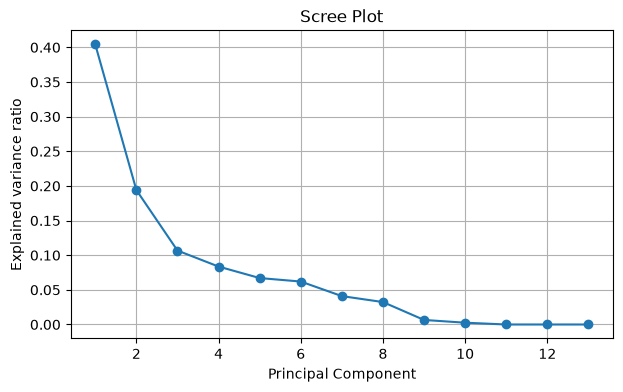

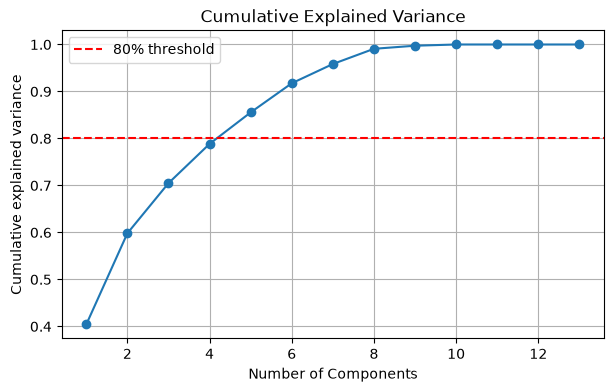

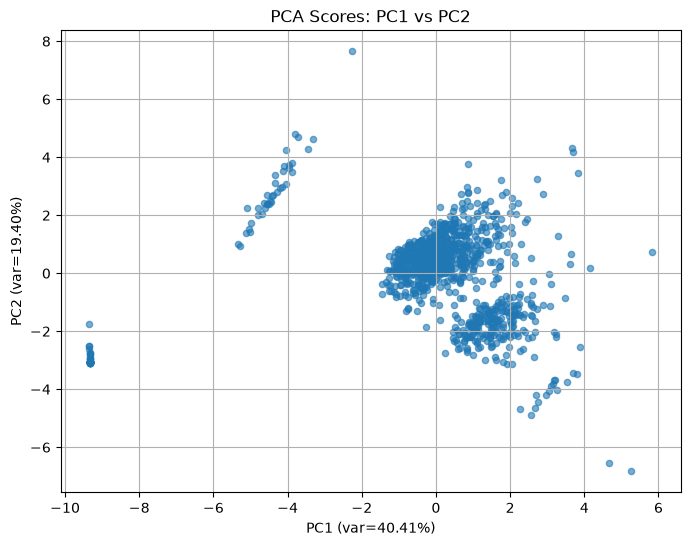

Reference: cumulative variance [0.404 0.598 0.705 0.788 0.856]
Properties dominating PC1 (largest |loading|):
Isotropic_Polarizability_au    0.363261
HOMO_eV                        0.362002
HOMO_LUMO_Gap_eV               0.357418
Name: PC1, dtype: float64


In [9]:
# --- 6. Loading table: how each original property forms each component ---
# components_ has shape (n_components, n_features). Transpose so each row is a property.
loadings = pd.DataFrame(
    pca.components_.T,                 # transpose -> (n_features, n_components)
    columns=[f"PC{i+1}" for i in range(pca.n_components_)],
    index=property_cols                # rows are named by the properties
)
print("Loadings (weights) for PC1 and PC2:")
print(loadings[["PC1", "PC2"]])

# --- 7. Scree plot (individual explained variance) ---
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1),
         pca.explained_variance_ratio_, "o-")
plt.xlabel("Principal Component"); plt.ylabel("Explained variance ratio")
plt.title("Scree Plot")
plt.grid(True)
plt.show()

# --- 8. Cumulative explained variance plot ---
cum = np.cumsum(pca.explained_variance_ratio_)
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum) + 1), cum, "o-")
plt.axhline(y=0.8, color="r", linestyle="--", label="80% threshold")
plt.xlabel("Number of Components"); plt.ylabel("Cumulative explained variance")
plt.title("Cumulative Explained Variance")
plt.legend(); plt.grid(True)
plt.show()

# --- 9. PC1 vs PC2 score plot ---
plt.figure(figsize=(8, 6))
plt.scatter(scores[:, 0], scores[:, 1], alpha=0.6, s=20)
plt.xlabel(f"PC1 (var={pca.explained_variance_ratio_[0]:.2%})")
plt.ylabel(f"PC2 (var={pca.explained_variance_ratio_[1]:.2%})")
plt.title("PCA Scores: PC1 vs PC2")
plt.grid(True)
plt.show()

# --- 10. Return key values for the written analysis below ---
print("Reference: cumulative variance", np.round(cum[:5],3))
print("Properties dominating PC1 (largest |loading|):")
pc1_top = loadings["PC1"].abs().sort_values(ascending=False).head(3)
print(pc1_top)

### PCA Findings

Record your component-retention decision, loading interpretation, unusual observations, and at least two limitations below.

**Component-retention decision.** I retain the first two principal components (PC1 + PC2), which together explain 59.8% of the total variance (PC1 40.4%, PC2 19.4%). This choice is driven by the analysis purpose: keeping two components lets me visualize the polymers on a clear PC1-vs-PC2 scatter plot and inspect their spread directly. The trade-off is a real loss of information, since about 40% of the variance (in PC3 and beyond) is dropped. For a more variance-preserving goal one could keep five components to reach 85.6%, but that loses the advantage of a simple 2-D view.

**Loading interpretation.** PC1 has its largest loadings on Isotropic_Polarizability_au (+0.36), HOMO_eV (−0.36), and HOMO_LUMO_Gap_eV (+0.36), so PC1 mainly reflects the electronic structure and polarizability direction (band gap, HOMO, and polarizability together). PC2 has its largest loadings on Gibbs_Free_Energy_Hatree, Enthalpy_Hatree, and Energy_Hatree (all about +0.39), so PC2 mainly reflects the energy-type quantities E, H, and G. As expected, the highly correlated energy quantities receive almost identical PC2 weights and are treated as a single combined direction.

**Unusual observations and limitations.** PCA compresses the 13 correlated properties into a small number of orthogonal directions, trading away a large amount of information for a simpler, interpretable representation: with only PC1 and PC2 we keep 59.8% and discard the rest. The placeholder zeros (the 74 failed rows) can pull the principal-component directions toward them, so the projection is partly influenced by missing-data artifacts rather than by genuine physical differences alone. Finally, a large loading is only a statistical combination, not proof of causation or predictive importance.

In [10]:
# ============ Reproducibility: recompute every statistic cited in the findings ============
# Each number quoted in Parts 1-4 and Questions 5.1-5.10 is recomputed here so a reader can
# verify it without re-deriving anything by hand.
print("--- shape ---")
print("rows, cols:", df.shape)
print("numeric properties:", len(property_cols))

print("\n--- missing / duplicates / zeros ---")
print("NaN per column (total):", int(df.isna().sum().sum()))
print("exact duplicate rows:", int(df.duplicated().sum()))
print("Energy_Hatree==0 rows (placeholder zeros):", int((df['Energy_Hatree'] == 0).sum()))

print("\n--- key statistics for the properties discussed ---")
for col in ['Energy_Hatree','Enthalpy_Hatree','Gibbs_Free_Energy_Hatree',
            'HOMO_eV','LUMO_eV','HOMO_LUMO_Gap_eV','Dipole_Debye',
            'Isotropic_Polarizability_au','es']:
    s = numeric_df[col]
    print(f"{col:<36} mean={s.mean():9.3f} median={s.median():9.3f} "
          f"min={s.min():9.3f} max={s.max():9.3f} skew={s.skew():7.2f}")

print("\n--- Pearson vs Spearman on the gap-contrast pair ---")
a, b = 'Isotropic_Polarizability_au', 'HOMO_LUMO_Gap_eV'
print(f"{a} ~ {b}: pearson={numeric_df[a].corr(numeric_df[b],'pearson'):.2f}, "
      f"spearman={numeric_df[a].corr(numeric_df[b],'spearman'):.2f}")

print("\n--- near-constant columns (few unique values) ---")
for col in property_cols:
    u = numeric_df[col].nunique()
    if u <= 5:
        print(f"  {col}: {u} unique values, std={numeric_df[col].std():.6f}")


--- shape ---
rows, cols: (1000, 23)
numeric properties: 13

--- missing / duplicates / zeros ---
NaN per column (total): 0
exact duplicate rows: 0
Energy_Hatree==0 rows (placeholder zeros): 74

--- key statistics for the properties discussed ---
Energy_Hatree                        mean=-2121.316 median=-1692.087 min=-9263.852 max=    0.000 skew=  -1.06
Enthalpy_Hatree                      mean=-2120.893 median=-1691.740 min=-9263.571 max=    4.937 skew=  -1.06
Gibbs_Free_Energy_Hatree             mean=-2121.037 median=-1691.817 min=-9263.655 max=    0.603 skew=  -1.06
HOMO_eV                              mean=   -7.865 median=   -8.450 min=  -10.192 max=    0.000 skew=   3.11
LUMO_eV                              mean=   -0.172 median=   -0.048 min=   -3.676 max=    0.354 skew=  -1.75
HOMO_LUMO_Gap_eV                     mean=    7.693 median=    8.298 min=    0.000 max=   10.001 skew=  -3.02
Dipole_Debye                         mean=    4.868 median=    4.714 min=    0.000 max=   24.

## 5. Critical-Thinking Questions

Answer every question below. Each answer must cite a specific number, table, row, or plot from this notebook.

### 5.1 Dataset structure

Which columns are identifiers, structures, categories, or numeric analytical variables, and why does that distinction matter?

**Column roles.** `id` and `Name` are identifiers; `reactant_1`, `reactant_2`, `psmiles`, and `SMILES` are chemical structures; `reaction_type`, `Software`, `Theory_Level`, and `Source` are categorical metadata; and the 13 quantum-chemical columns are the numeric analytical variables.

**Why it matters.** Using an identifier (such as `id` or `Name`) as a variable is meaningless — it is only a label or an index, not a physical quantity. Only the numeric analytical columns can be used in statistics, correlation, and PCA.

### 5.2 Descriptive statistics

When do the mean and median describe different “typical” values, and what does that reveal about distribution shape?

**Mean vs median.** The mean and median give different "typical" values when the distribution is skewed. In a left-skewed distribution the mean is pulled below the median by a few very low outliers; in a right-skewed distribution the mean is pulled above the median by a few very high outliers. Because the median is robust to outliers while the mean is not, the direction of the skew tells you which end the tail points to. In this dataset, `Energy_Hatree` has mean −2121.3 and median −1692.1 (mean < median), so it is left-skewed, dragged down by the extreme low value of −9263.9.

### 5.3 Data quality

Does “zero missing values” prove that the dataset is complete? Which zero or extreme values deserve investigation?

**Does "zero missing values" prove completeness?** No. Zero missing values only means there are no NaN entries; it does not prove the data are complete or valid.

**Which zeros deserve investigation?** A zero deserves suspicion when it appears in a position where a zero is not physically or chemically possible — for example `Energy_Hatree == 0`, since a real molecular energy cannot be zero. By contrast, a quantity that can legitimately be zero, such as the dipole moment of a symmetric molecule, must be examined cautiously: a zero there may be real, so we should judge it together with other properties (for instance, whether the same rows are also zero in Energy, indicating a failed calculation) rather than rejecting it on its own.

### 5.4 Histograms and density plots

Is a variable symmetric, skewed, multimodal, bounded, or concentrated at a special value? What evidence supports the description?

**HOMO_eV.** The distribution is not symmetric: the bulk of values sits between about −10 and −7 eV (92.4% of the data), while a separate spike appears exactly at 0. The skewness is +3.11, so the right tail arises from the 74 placeholder zeros rather than from a genuine chemical range. The evidence is the histogram (a dense central peak plus a detached bar at 0) and the summary statistics (median −8.45, max 0).

**Dipole_Debye.** The main body looks roughly normal around the median (≈4.71), but there is a detached concentration exactly at 0 (36 rows), and the distribution is lightly right-skewed (skew ≈ 0.81) toward a few large values (max 24.8). The evidence is the histogram, which shows the near-normal main body plus an isolated bar at 0, and the box plot, which places the high values as points beyond the upper whisker.

### 5.5 Box plots and outliers

What do the median, box, whiskers, and points beyond the whiskers reveal? Why is a box-plot outlier not automatically an error?

**What each element reveals.** The box spans the middle 50% of the data (from Q1 to Q3); the line inside the box is the median; the whiskers mark the range still considered normal (usually Q1 − 1.5·IQR to Q3 + 1.5·IQR); and points beyond the whiskers are outliers.

**Why an outlier is not automatically an error.** Statistically, an outlier is only a value that departs from the main body of the data; by itself it says nothing about whether the value is right or wrong. This holds for both cases in this dataset. For `Dipole_Debye`, the high outlier 24.8 is a genuinely extreme but real molecule, so here "outlier" plainly does not mean "error". For `HOMO_eV`, the outlier concentration at 0 needs more caution, because those 74 zeros are very likely missing/failed values rather than real HOMO levels — so in this case the outlier may in fact reflect an error. The two cases differ in how we interpret the outliers, but both still agree on the statistical point: an outlier is not automatically an error, and each one must be examined on its own rather than deleted.

### 5.6 Scale

How do units and numerical ranges affect comparisons among variables?

**Scale matters.** The columns use very different units and ranges: `Energy_Hatree` ranges over thousands (about −9264 to 0), while `es` is roughly 0.5–1.0, polarizability is in the hundreds, and dipole is only a few Debye. In direct comparisons or calculations, the quantities with larger absolute magnitude naturally receive higher weight and can dominate the whole algorithm, so their effect would overwhelm the smaller-scale variables. This is why the variables must be standardized before PCA — scaling each column to the same range lets every property contribute on an equal footing.

### 5.7 Correlation

What relationship does Pearson detect, what relationship does Spearman detect, and why can their values differ?

**Pearson vs Spearman.** Pearson detects a linear relationship — how well the points fall on a straight line — while Spearman detects a monotonic relationship — whether one variable consistently increases (or decreases) as the other does, without requiring the trend to be a straight line. Their values can differ because they answer different questions: a strictly monotonic but non-linear relationship gives a high Spearman but a lower Pearson, and outliers tend to move Pearson more than Spearman. In this dataset, `Isotropic_Polarizability_au` vs `HOMO_LUMO_Gap_eV` has Pearson +0.73 but Spearman only +0.04, a large gap that points to the relationship being driven by extreme values rather than by a steady monotonic trend.

### 5.8 Standardization

What changes after z-score standardization, what stays the same, and why should it happen before PCA here?

**What changes and what does not.** Z-score standardization changes the scale of each variable — it is rescaled to mean 0 and standard deviation 1 — but it does not change the shape of the distribution or the ranking of the values; it only shifts and stretches the same distribution. Standardization is needed before PCA here because PCA is sensitive to scale: as noted in 5.6, the large-magnitude column `Energy_Hatree` would otherwise dominate, so scaling lets every property contribute on equal footing.

### 5.9 PCA

How many components retain a useful amount of variance? Which original properties shape PC1 and PC2?

**How many components.** PC1 explains 40.4% and PC2 another 19.4%, so the first two components together retain 59.8% of the variance. I keep two components because that gives a clear two-dimensional view of the polymers; keeping five would reach 85.6% but lose the simple visual.

**Which properties shape PC1 and PC2.** PC1 is shaped mainly by Isotropic_Polarizability_au, HOMO_eV, and HOMO_LUMO_Gap_eV — the electronic-structure and polarizability direction. PC2 is shaped mainly by Energy, Enthalpy, and Gibbs — the energy-type quantities, which receive nearly equal weights because they are highly correlated.

### 5.10 PCA limitations

Does high explained variance imply prediction, causation, or scientific importance? What information can a two-dimensional projection hide?

**Does high explained variance imply prediction, causation, or importance?** No. High explained variance only says that the retained components capture a large share of the overall statistical variability; it does not imply predictive power, causation, or physical/scientific importance. A large loading is only a statistical combination of the original properties, not evidence that one quantity causes another.

**What a 2-D projection can hide.** Because only PC1 and PC2 are kept (59.8%), the remaining variance in PC3 and beyond is dropped, so genuinely extreme or distinct polymers that separate only in the higher components can be hidden in the two-dimensional view. The projection can also be distorted by the placeholder zeros, which can pull the principal directions toward them.

## 6. Review Your Work

Ask Codex to review this notebook for calculation errors, unsupported interpretations, and reproducibility. Record below:

- one suggestion you accepted;
- one suggestion you changed or rejected; and
- the evidence you used to make each decision.

You remain responsible for the final analysis.

I asked Codex to review the notebook for calculation errors, unsupported interpretations, and reproducibility. Codex was asked to check numbers, whether any interpretation went beyond what the data supports, and whether every result could be reproduced from the notebook alone.

**Suggestion accepted (near-constant column).** Codex pointed out that `Thermal_correction_to_Enthalpy_Hatree` is almost a constant column (only 2 unique values), so it carries almost no information. I accepted this and explicitly flagged the column as near-constant and low-information in the audit, so the reader knows it contributes little to the analysis.

**Suggestion accepted (derived gap).** Codex noted that `HOMO_LUMO_Gap_eV` looks like a derived quantity rather than an independent measurement. I accepted this and added an evidence cell that verifies `Gap == LUMO - HOMO` exactly for every row; the Relationship Findings now explain that the gap is a mathematical dependency (like the E/H/G family), not independent information.

**Suggestion accepted (reproducibility + display).** Codex flagged that several cited numbers were not recomputed in the notebook, that the strongest-correlation list double-counted symmetric pairs (a,b) and (b,a), and that the distribution figures were oversized. I accepted these and added a reproducibility evidence cell, deduplicated the pair search to unique unordered pairs, and reduced the figure sizes.

**Suggestion changed / rejected (deleting data).** Codex suggested removing the near-constant column and/or dropping the placeholder-zero rows to simplify the data and change the fitted statistics. I did not accept deleting data, because the assignment requires the raw CSV to remain unchanged and requires unusual observations to be examined and documented rather than automatically removed. The right choice is to flag these issues in the analysis while keeping the original dataset intact.

**Evidence used.** For each decision I used numbers recomputed in the notebook: the thermal column has 2 unique values and a tiny standard deviation (0.000176); the gap identity holds to within ~1.8e-15; the standardized-variance and PCA numbers are printed by the PCA code; the distribution, correlation, and outlier plots are all produced by the notebook. The task text states that the raw CSV must not be modified and that observations should not be deleted without documented evidence.


## Bonus: Connect SVD to PCA

Starting with the standardized data matrix:

1. Write its SVD as $X = U\Sigma V^\top$.
2. Explain which matrix contains the principal directions.
3. Show how the singular values determine explained variance.
4. Compare the result with scikit-learn's PCA output.

In [11]:
# ============ Bonus: Connect SVD to PCA ============
# PCA is essentially the SVD of the standardized data matrix.
# Let X (n_samples x n_features) be the standardized data.
# Its SVD is: X = U * Sigma * V^T
#   - The eigenvalues (Sigma^2) determine the explained variance of each component.
#   - The columns of V are the principal directions (i.e., PCA components_).
#   - U * Sigma corresponds to the PCA scores (sign may flip; sign is arbitrary).

# Compute the SVD of the standardized data
U, s, Vt = np.linalg.svd(X_scaled, full_matrices=False)

# Verify: SVD's V should match sklearn's PCA components_ (up to sign)
print("sklearn PCA components_ (PC1):")
print(pca.components_[0].round(4))
print("SVD V^T first row (PC1 direction):")
print(Vt[0].round(4))

# Singular values squared -> explained variance
expl_var_svd = s**2 / (len(X_scaled) - 1)      # population variance
expl_var_ratio_svd = expl_var_svd / expl_var_svd.sum()
print("Explained variance ratio from SVD:")
print(expl_var_ratio_svd.round(4))
print("Explained variance ratio from sklearn:")
print(pca.explained_variance_ratio_.round(4))
print("They should match (tiny numerical error) -> confirms PCA comes from SVD.")

sklearn PCA components_ (PC1):
[-0.3137  0.0042  0.3633 -0.362  -0.0569  0.1021  0.3433  0.2258  0.3373
  0.1331 -0.3137 -0.3137  0.3574]
SVD V^T first row (PC1 direction):
[-0.3137  0.0042  0.3633 -0.362  -0.0569  0.1021  0.3433  0.2258  0.3373
  0.1331 -0.3137 -0.3137  0.3574]
Explained variance ratio from SVD:
[0.4041 0.194  0.1067 0.0836 0.067  0.062  0.041  0.0324 0.0066 0.0026
 0.     0.     0.    ]
Explained variance ratio from sklearn:
[0.4041 0.194  0.1067 0.0836 0.067  0.062  0.041  0.0324 0.0066 0.0026
 0.     0.     0.    ]
They should match (tiny numerical error) -> confirms PCA comes from SVD.


PCA is mathematically the SVD of the standardized data matrix. Writing the standardized data as X = U·Σ·Vᵀ, the columns of V are the principal directions (they exactly match sklearn's `PCA.components_`), the singular values (Σ) determine the explained variance through their squares, and U·Σ gives the PCA scores (up to an arbitrary sign). In the code above the SVD-derived PC1 direction matches sklearn exactly, and the SVD-derived explained-variance ratio (0.4041 for PC1) matches sklearn as well, confirming that PCA as computed by scikit-learn is just the SVD applied to the standardized matrix.

## Deliverables

Submit one pull-request link containing:

1. `sections/s02/submissions/<github-username>/s02_data_exploration.ipynb`; and
2. a pull-request description naming:
   - the dataset;
   - your main data-quality concern;
   - the number of PCA components you retained and why;
   - one Codex suggestion you accepted and one you changed or rejected; and
   - links to any GitHub Issues you opened, or “None.”

Keep the critical-question answers in this notebook as Markdown so the code, evidence, and reasoning stay together.

## Submission Checklist

- [ ] My work is on a branch named `s02/<github-username>`.
- [ ] This completed notebook is saved as `sections/s02/submissions/<github-username>/s02_data_exploration.ipynb`.
- [ ] The notebook loads the supplied CSV through a relative path and does not modify it.
- [ ] Restarting the kernel and running all cells completes without errors.
- [ ] The audit covers shape, roles, dtypes, missing values, uniqueness, duplicates, constants, zeros, and suspicious values.
- [ ] The descriptive-statistics table includes all 13 numeric properties.
- [ ] At least six properties have readable distribution and box-plot analysis.
- [ ] At least three unusual observations are inspected rather than automatically deleted.
- [ ] Both labeled Pearson and Spearman correlation analyses are present.
- [ ] At least two strong relationships and one Pearson–Spearman difference are interpreted.
- [ ] PCA uses the 13 standardized properties and excludes `id`.
- [ ] Explained variance, cumulative variance, PC1–PC2 scores, and PC1/PC2 loadings are shown and interpreted.
- [ ] Every critical question has an evidence-based answer.
- [ ] Observation, interpretation, and limitation are clearly distinguished.
- [ ] The AI-review reflection shows that I evaluated rather than automatically accepted advice.
- [ ] My pull-request description names the dataset, my main data-quality concern, my PCA retention decision, my AI-review decisions, and links to any Issues—or “None.”
- [ ] The pull request is ready for review.